# BahaPredict — Initial Rainfall Insights

## M4 — Initial Insights

This notebook analyzes the processed rainfall dataset generated during M3. The analysis focuses on three business questions related to extreme rainfall, monthly rainfall patterns, and cumulative rainfall across the 17 Philippine representative locations.

**Dataset:** `data/processed/rainfall_clean.csv`  
**Period:** January 1, 2026 – October 31, 2026  
**Scope:** One representative location per Philippine administrative region  
**Extreme rainfall threshold:** 50 mm/day

## 1. Load the Processed Dataset

In [1]:

from pathlib import Path
import pandas as pd
import os
import matplotlib.pyplot as plt

# Find the project root by locating the data folder
current = Path.cwd()

PROJECT_ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "data" / "processed" / "rainfall_clean.csv").exists()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/processed/rainfall_clean.csv. "
        "Check the notebook's working directory."
    )

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "rainfall_clean.csv"
FIGURE_DIR = PROJECT_ROOT / "output" / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)

df = pd.read_csv(DATA_PATH, parse_dates=["date"])

print(f"Records: {len(df):,}")
print(f"Regions: {df['region'].nunique()}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")


Project root: /Users/mark/Github/projects/dep-data-engineering-mark-cabael
Dataset path: /Users/mark/Github/projects/dep-data-engineering-mark-cabael/data/processed/rainfall_clean.csv
Records: 5,168
Regions: 17
Date range: 2026-01-01 to 2026-10-31


## 2. Data Overview

The M3 processed dataset contains daily precipitation observations for 17 representative locations. Each region contributes 304 daily observations covering January through October 2026, resulting in 5,168 records.

In [2]:
df.head()

,date,region,location,latitude,longitude,precipitation_mm,precipitation_missing,is_extreme
0,2026-01-01,BARMM,Cotabato City,7.205624,124.26396,12.3,False,False
1,2026-01-02,BARMM,Cotabato City,7.205624,124.26396,5.9,False,False
2,2026-01-03,BARMM,Cotabato City,7.205624,124.26396,7.1,False,False
3,2026-01-04,BARMM,Cotabato City,7.205624,124.26396,18.1,False,False
4,2026-01-05,BARMM,Cotabato City,7.205624,124.26396,0.9,False,False


## 3. Business Question 1 — Which representative locations recorded the most extreme rainfall days?

An extreme rainfall day is defined in this project as a day with precipitation of at least 50 mm.

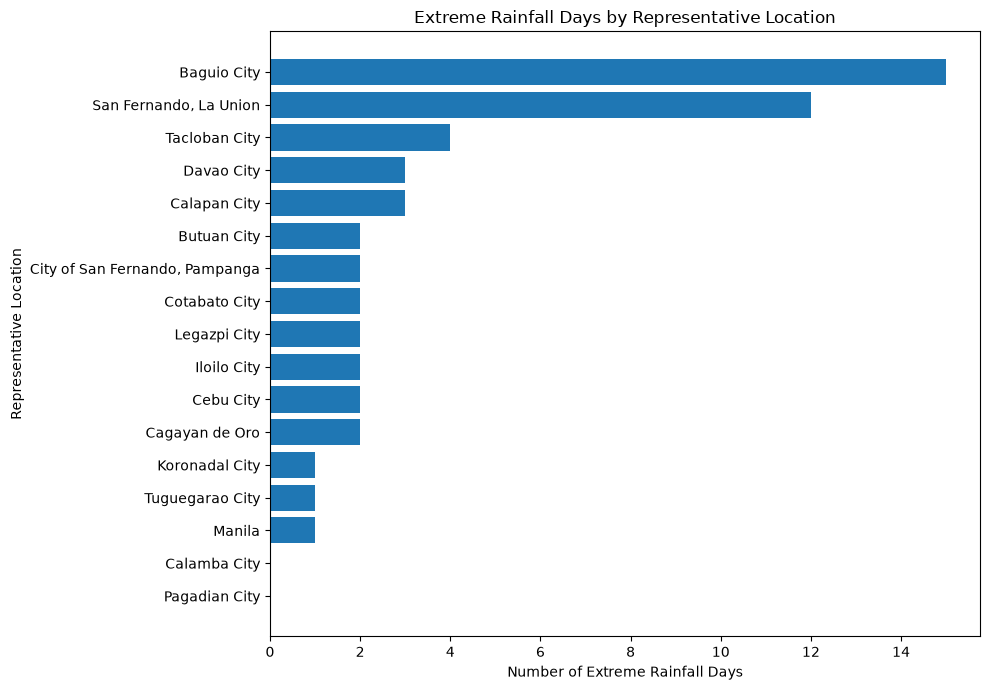

,region,location,extreme_rainfall_days
1,CAR,Baguio City,15
4,Region I (Ilocos),"San Fernando, La Union",12
12,Region VIII (Eastern Visayas),Tacloban City,4
14,Region XI (Davao Region),Davao City,3
2,MIMAROPA,Calapan City,3
0,BARMM,Cotabato City,2
16,Region XIII (Caraga),Butuan City,2
6,Region III (Central Luzon),"City of San Fernando, Pampanga",2
9,Region V (Bicol),Legazpi City,2
10,Region VI (Western Visayas),Iloilo City,2


In [3]:
q1 = (
    df.groupby(["region", "location"], as_index=False)["is_extreme"]
    .sum()
    .rename(columns={"is_extreme": "extreme_rainfall_days"})
    .sort_values("extreme_rainfall_days", ascending=True)
)

plt.figure(figsize=(10, 7))
plt.barh(q1["location"], q1["extreme_rainfall_days"])
plt.xlabel("Number of Extreme Rainfall Days")
plt.ylabel("Representative Location")
plt.title("Extreme Rainfall Days by Representative Location")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "01_extreme_rainfall_days.png"), dpi=300, bbox_inches="tight")
plt.show()

q1.sort_values("extreme_rainfall_days", ascending=False)

### Interpretation

Baguio City recorded the highest number of extreme rainfall days at 15, followed by San Fernando, La Union with 12. Tacloban City recorded four extreme rainfall days, while Calapan City and Davao City recorded three each.

Most other representative locations recorded two or fewer extreme rainfall days during the January–October 2026 period. Two locations, Calamba City and Pagadian City, recorded no days meeting the project's extreme rainfall threshold.

This shows that extreme rainfall events were not evenly distributed across the selected representative locations. However, the results describe the selected locations only and should not be interpreted as measurements for every part of their respective regions.

## 4. Business Question 2 — Which months had the highest average daily rainfall?

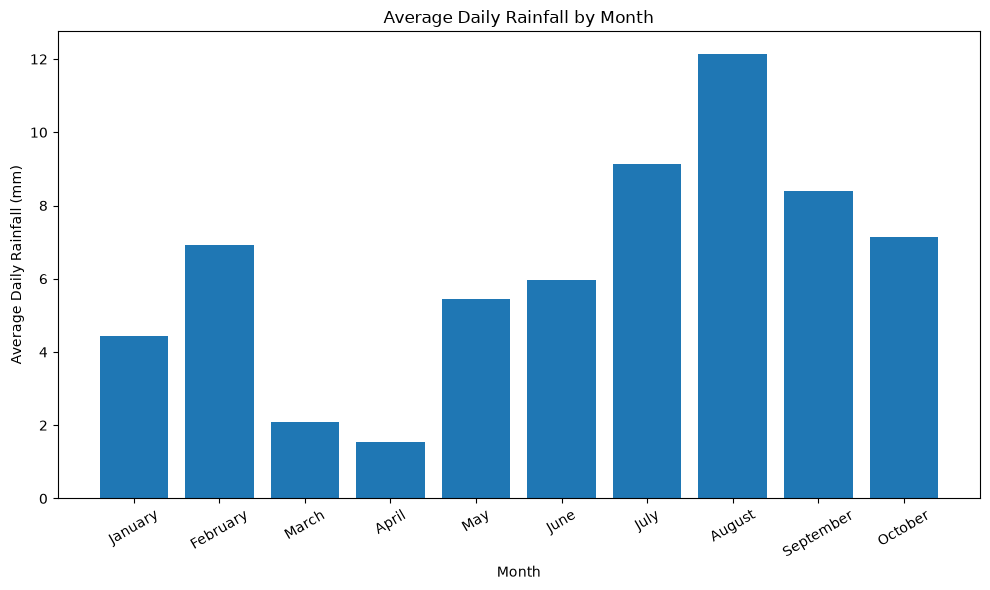

,month_name,average_rainfall_mm
0,January,4.443264
1,February,6.924370
2,March,2.077040
3,April,1.550980
4,May,5.443454
5,June,5.963529
6,July,9.133586
7,August,12.149715
8,September,8.383529
9,October,7.132448


In [4]:
df["month"] = df["date"].dt.month
month_names = {
    1: "January", 2: "February", 3: "March", 4: "April",
    5: "May", 6: "June", 7: "July", 8: "August", 9: "September",
    10: "October"
}

q2 = (
    df.groupby("month", as_index=False)["precipitation_mm"]
    .mean()
    .rename(columns={"precipitation_mm": "average_rainfall_mm"})
)
q2["month_name"] = q2["month"].map(month_names)

plt.figure(figsize=(10, 6))
plt.bar(q2["month_name"], q2["average_rainfall_mm"])
plt.xlabel("Month")
plt.ylabel("Average Daily Rainfall (mm)")
plt.title("Average Daily Rainfall by Month")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "02_average_rainfall_by_month.png"), dpi=300, bbox_inches="tight")
plt.show()

q2[["month_name", "average_rainfall_mm"]]

### Interpretation

August had the highest average daily rainfall at 12.15 mm, followed by July at 9.13 mm and September at 8.38 mm. April had the lowest average daily rainfall at 1.55 mm.

The results indicate variation in average daily rainfall across the ten observed months. August recorded the highest average, while rainfall averages generally increased during July through October compared with the drier months earlier in the year.

This pattern describes the observed representative locations during the selected period and does not establish a long-term seasonal trend.

## 5. Business Question 3 — Which representative locations recorded the highest total rainfall?

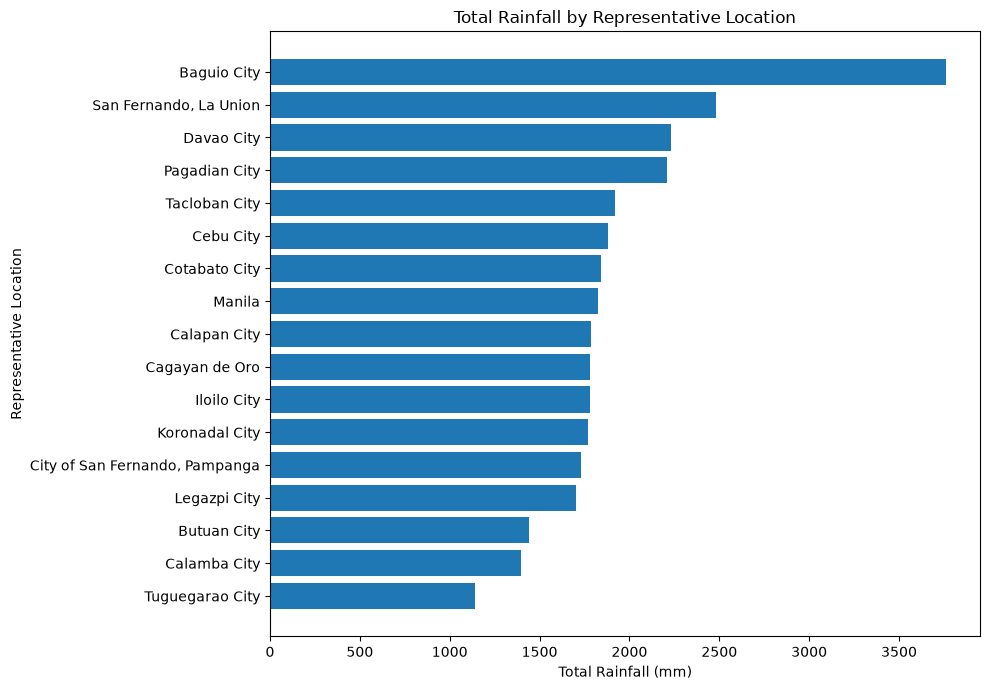

,region,location,total_rainfall_mm
1,CAR,Baguio City,3762.3
4,Region I (Ilocos),"San Fernando, La Union",2484.0
14,Region XI (Davao Region),Davao City,2230.8
8,Region IX (Zamboanga Peninsula),Pagadian City,2210.7
12,Region VIII (Eastern Visayas),Tacloban City,1917.7
11,Region VII (Central Visayas),Cebu City,1881.5
0,BARMM,Cotabato City,1843.4
3,NCR,Manila,1826.7
2,MIMAROPA,Calapan City,1788.6
13,Region X (Northern Mindanao),Cagayan de Oro,1779.9


In [5]:
q3 = (
    df.groupby(["region", "location"], as_index=False)["precipitation_mm"]
    .sum()
    .rename(columns={"precipitation_mm": "total_rainfall_mm"})
    .sort_values("total_rainfall_mm", ascending=True)
)

plt.figure(figsize=(10, 7))
plt.barh(q3["location"], q3["total_rainfall_mm"])
plt.xlabel("Total Rainfall (mm)")
plt.ylabel("Representative Location")
plt.title("Total Rainfall by Representative Location")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "03_total_rainfall_by_location.png"), dpi=300, bbox_inches="tight")
plt.show()

q3.sort_values("total_rainfall_mm", ascending=False)

### Interpretation

Baguio City recorded the highest cumulative rainfall at 3,762.3 mm during the study period. San Fernando, La Union ranked second with 2,484.0 mm, while Davao City ranked third with 2,230.8 mm.

Pagadian City ranked fourth with 2,210.7 mm, followed by Tacloban City with 1,917.7 mm.

The difference in cumulative rainfall shows substantial variation among the representative locations. These totals can help identify locations for further investigation, but they should not be used alone to determine flood risk or other hazards.

## 6. Key Inferences

- Baguio City ranked highest in both extreme rainfall days and total rainfall during the study period.
- San Fernando, La Union also showed relatively high rainfall exposure, ranking second for both extreme rainfall days and total rainfall.
- August had the highest average daily rainfall across the 17 representative locations, while April had the lowest.
- Pagadian City recorded relatively high cumulative rainfall despite having no days that met the project's extreme rainfall threshold.
- Rainfall patterns varied considerably between representative locations, suggesting that rainfall-related analysis should account for geographic differences rather than relying on a single national average.

These are observational findings from the available dataset. They do not establish that rainfall caused flooding, infrastructure damage, or other impacts. Additional variables such as elevation, drainage, land use, river conditions, soil characteristics, and actual flood observations would be needed to assess those relationships.

## 7. Limitations

- Each administrative region is represented by one selected geographic location rather than region-wide rainfall measurements.
- The analysis covers January 1 through October 31, 2026 only.
- The 50 mm/day extreme rainfall threshold is a project-specific analytical definition.
- Rainfall alone cannot determine flood risk or establish causality.
- Ten months of observations are insufficient to establish long-term climatological trends.
- Longer historical periods and additional geographic points would improve the reliability of future analysis.

## 8. Output Figures

The three charts generated by this notebook are saved in `output/figures/`:

- `01_extreme_rainfall_days.png`
- `02_average_rainfall_by_month.png`
- `03_total_rainfall_by_location.png`